# Titles and survival

Title taken from the `Name` column of `train.csv` (the only file with `Survived`).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv(next(p / "data/train.csv" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/train.csv").exists()))
train["Title"] = train["Name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip()

summary = (
    train.groupby("Title")["Survived"]
    .agg(people="size", survived="sum")
    .assign(died=lambda d: d["people"] - d["survived"])
    .assign(
        survived_pct=lambda d: 100 * d["survived"] / d["people"],
        died_pct=lambda d: 100 * d["died"] / d["people"],
    )
    .sort_values(["people", "survived_pct"], ascending=[False, False])
)
summary.round(1)

,people,survived,died,survived_pct,died_pct
Title,,,,,
Mr,517,81,436,15.7,84.3
Miss,182,127,55,69.8,30.2
Mrs,125,99,26,79.2,20.8
Master,40,23,17,57.5,42.5
Dr,7,3,4,42.9,57.1
Rev,6,0,6,0.0,100.0
Mlle,2,2,0,100.0,0.0
Col,2,1,1,50.0,50.0
Major,2,1,1,50.0,50.0


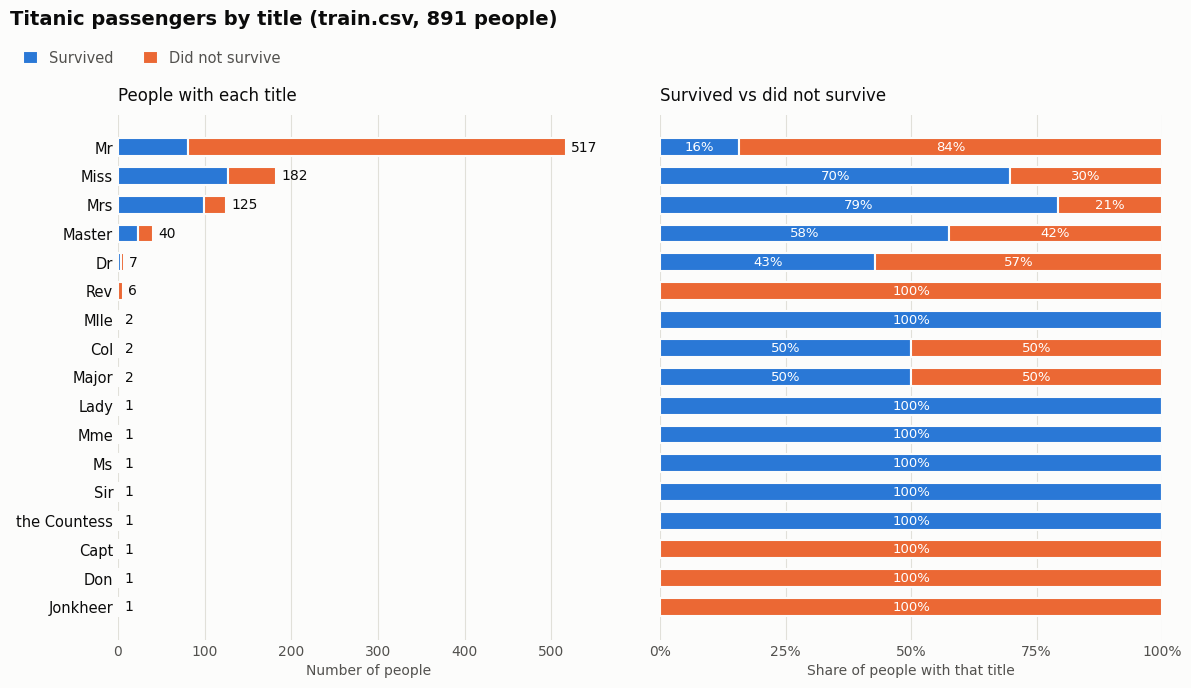

In [2]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
SURVIVED, DIED = "#2a78d6", "#eb6834"

titles = summary.index.tolist()
y = range(len(titles))
bar = dict(height=0.62, edgecolor=SURFACE, linewidth=1.5)

fig, (ax_n, ax_pct) = plt.subplots(
    1, 2, figsize=(12, 7), sharey=True, facecolor=SURFACE,
    gridspec_kw={"width_ratios": [1, 1], "wspace": 0.08},
)

# Left: number of people, split by outcome
ax_n.barh(y, summary["survived"], color=SURVIVED, label="Survived", **bar)
ax_n.barh(y, summary["died"], left=summary["survived"], color=DIED, label="Did not survive", **bar)
for i, n in enumerate(summary["people"]):
    ax_n.text(n + 6, i, f"{n:,}", va="center", ha="left", fontsize=10, color=INK)
ax_n.set_xlim(0, summary["people"].max() * 1.12)
ax_n.set_xlabel("Number of people", color=MUTED)
ax_n.set_title("People with each title", loc="left", fontsize=12, color=INK, pad=10)

# Right: share of each title that survived vs not
ax_pct.barh(y, summary["survived_pct"], color=SURVIVED, **bar)
ax_pct.barh(y, summary["died_pct"], left=summary["survived_pct"], color=DIED, **bar)
for i, (s, d) in enumerate(zip(summary["survived_pct"], summary["died_pct"])):
    if s >= 10:
        ax_pct.text(s / 2, i, f"{s:.0f}%", va="center", ha="center", fontsize=9.5, color="white")
    if d >= 10:
        ax_pct.text(s + d / 2, i, f"{d:.0f}%", va="center", ha="center", fontsize=9.5, color="white")
ax_pct.set_xlim(0, 100)
ax_pct.set_xticks(range(0, 101, 25))
ax_pct.set_xticklabels([f"{t}%" for t in range(0, 101, 25)])
ax_pct.set_xlabel("Share of people with that title", color=MUTED)
ax_pct.set_title("Survived vs did not survive", loc="left", fontsize=12, color=INK, pad=10)

ax_n.set_yticks(list(y))
ax_n.set_yticklabels(titles, fontsize=10.5, color=INK)
ax_n.invert_yaxis()

for ax in (ax_n, ax_pct):
    ax.set_facecolor(SURFACE)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", colors=MUTED, length=0)
    ax.tick_params(axis="y", length=0)
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(False)

fig.suptitle("Titanic passengers by title (train.csv, 891 people)",
             x=0.02, y=0.99, ha="left", fontsize=14, fontweight="bold", color=INK)
fig.legend(*ax_n.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.02, 0.95),
           ncol=2, frameon=False, fontsize=10.5, labelcolor=MUTED, handlelength=1, handleheight=1)
fig.subplots_adjust(top=0.84, left=0.11, right=0.98, bottom=0.09)
plt.show()